# Cell 1 — Libraries

In [1]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [7]:
import glob
import os

csv_files = sorted(glob.glob("KT_GameBox_*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Total CSV files: 10
KT_GameBox_1.csv
KT_GameBox_10.csv
KT_GameBox_2.csv
KT_GameBox_3.csv
KT_GameBox_4.csv
KT_GameBox_5.csv
KT_GameBox_6.csv
KT_GameBox_7.csv
KT_GameBox_8.csv
KT_GameBox_9.csv


# Cell 2 — Read all 10 CSV files

In [2]:
folder = "."

csv_files = sorted(
    glob.glob(os.path.join(folder, "KT_GameBox_*.csv"))
)

print("CSV files found:", len(csv_files))

for f in csv_files:
    print(os.path.basename(f))

CSV files found: 10
KT_GameBox_1.csv
KT_GameBox_10.csv
KT_GameBox_2.csv
KT_GameBox_3.csv
KT_GameBox_4.csv
KT_GameBox_5.csv
KT_GameBox_6.csv
KT_GameBox_7.csv
KT_GameBox_8.csv
KT_GameBox_9.csv


In [9]:
import pandas as pd
import glob
import os
import re

# Only files like KT_GameBox_1.csv ... KT_GameBox_10.csv
files = []

for file in glob.glob("KT_GameBox_*.csv"):
    name = os.path.basename(file)
    match = re.fullmatch(r"KT_GameBox_(\d+)\.csv", name)

    if match:
        files.append((int(match.group(1)), file))

# Sort: 1, 2, 3, ... 10
files.sort()

output_file = "KT_GameBox_Merged.csv"

# Remove old merged file if it exists
if os.path.exists(output_file):
    os.remove(output_file)

first_file = True

for number, file in files:
    print(f"Merging file {number}: {os.path.basename(file)}")

    for chunk in pd.read_csv(
        file,
        chunksize=100_000,
        low_memory=False,
        engine="c"
    ):
        chunk.to_csv(
            output_file,
            mode="w" if first_file else "a",
            header=first_file,
            index=False
        )

        first_file = False

print("\n✅ Merge completed successfully!")
print("Output file:", output_file)

Merging file 1: KT_GameBox_1.csv
Merging file 2: KT_GameBox_2.csv
Merging file 3: KT_GameBox_3.csv
Merging file 4: KT_GameBox_4.csv
Merging file 5: KT_GameBox_5.csv
Merging file 6: KT_GameBox_6.csv
Merging file 7: KT_GameBox_7.csv
Merging file 8: KT_GameBox_8.csv
Merging file 9: KT_GameBox_9.csv
Merging file 10: KT_GameBox_10.csv

✅ Merge completed successfully!
Output file: KT_GameBox_Merged.csv


In [10]:
import pandas as pd

df = pd.read_csv(
    "KT_GameBox_Merged.csv",
    nrows=10
)

print("Columns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
print(df)

print("\nShape (first 10 rows loaded):")
print(df.shape)

Columns:
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info']

First 10 rows:
   No.                        Time          Source     Destination Protocol  \
0    1  2022-10-05 14:28:49.564595       192.0.0.2    10.215.173.2      TCP   
1    2  2022-10-05 14:28:51.317163    10.215.173.1    10.215.173.2      DNS   
2    3  2022-10-05 14:28:51.348247    10.215.173.2    10.215.173.1      DNS   
3    4  2022-10-05 14:28:51.351537    10.215.173.1  211.252.120.14      TCP   
4    5  2022-10-05 14:28:51.372722  211.252.120.14    10.215.173.1      TCP   
5    6  2022-10-05 14:28:51.372868    10.215.173.1  211.252.120.14      TCP   
6    7  2022-10-05 14:28:51.382909    10.215.173.1  211.252.120.14  TLSv1.3   
7    8  2022-10-05 14:28:51.383112  211.252.120.14    10.215.173.1      TCP   
8    9  2022-10-05 14:28:51.398323    10.215.173.1    10.215.173.2      DNS   
9   10  2022-10-05 14:28:51.413707  211.252.120.14    10.215.173.1  TLSv1.3   

   Length                         

# Step 4 — Dataset analysis

In [11]:
import pandas as pd

protocol_counts = {}
missing_counts = {}
total_rows = 0

for chunk in pd.read_csv(
    "KT_GameBox_Merged.csv",
    chunksize=100_000,
    low_memory=False
):
    total_rows += len(chunk)

    # Protocol count
    counts = chunk["Protocol"].value_counts(dropna=False)

    for protocol, count in counts.items():
        protocol_counts[protocol] = (
            protocol_counts.get(protocol, 0) + count
        )

    # Missing value count
    for col in chunk.columns:
        missing_counts[col] = (
            missing_counts.get(col, 0)
            + chunk[col].isna().sum()
        )

print("Total rows:", total_rows)

print("\nProtocol distribution:")
print(
    pd.Series(protocol_counts)
    .sort_values(ascending=False)
)

print("\nMissing values:")
print(
    pd.Series(missing_counts)
)

Total rows: 38096046

Protocol distribution:
UDP        34939465
TCP         3097314
TLSv1         21358
SSLv2         21342
R-GOOSE        7642
TLSv1.3        7597
THRIFT         1009
TLSv1.2         133
DNS             102
SMPP             38
FMTP             31
TPKT              8
Q.931             4
CLTP              3
dtype: int64

Missing values:
No.               0
Time              0
Source            0
Destination       0
Protocol          0
Length            0
Info           7619
dtype: int64


In [12]:
protocol_counts = pd.Series(protocol_counts)

protocol_percentage = (
    protocol_counts
    .sort_values(ascending=False)
    .div(total_rows)
    .mul(100)
    .round(4)
)

print(protocol_percentage)

UDP        91.7142
TCP         8.1303
TLSv1       0.0561
SSLv2       0.0560
R-GOOSE     0.0201
TLSv1.3     0.0199
THRIFT      0.0026
TLSv1.2     0.0003
DNS         0.0003
SMPP        0.0001
FMTP        0.0001
TPKT        0.0000
Q.931       0.0000
CLTP        0.0000
dtype: float64


# Step 6 — TCP/UDP balanced dataset 

In [13]:
import pandas as pd

input_file = "KT_GameBox_Merged.csv"
output_file = "KT_GameBox_TCP_UDP_Balanced.csv"

samples_per_class = 500_000

tcp_count = 0
udp_count = 0
chunks = []

for chunk in pd.read_csv(
    input_file,
    chunksize=100_000,
    low_memory=False
):
    tcp = chunk[chunk["Protocol"] == "TCP"]
    udp = chunk[chunk["Protocol"] == "UDP"]

    # Take only what's still needed
    if tcp_count < samples_per_class:
        n = min(samples_per_class - tcp_count, len(tcp))
        if n > 0:
            chunks.append(tcp.sample(n=n, random_state=42))
            tcp_count += n

    if udp_count < samples_per_class:
        n = min(samples_per_class - udp_count, len(udp))
        if n > 0:
            chunks.append(udp.sample(n=n, random_state=42))
            udp_count += n

    if tcp_count >= samples_per_class and udp_count >= samples_per_class:
        break

balanced_df = pd.concat(chunks, ignore_index=True)

# Shuffle
balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

balanced_df.to_csv(
    output_file,
    index=False
)

print("TCP samples:", (balanced_df["Protocol"] == "TCP").sum())
print("UDP samples:", (balanced_df["Protocol"] == "UDP").sum())
print("Final shape:", balanced_df.shape)
print("Saved:", output_file)

TCP samples: 500000
UDP samples: 500000
Final shape: (1000000, 7)
Saved: KT_GameBox_TCP_UDP_Balanced.csv


# Step 7 — Balanced dataset check

In [14]:
import pandas as pd

df = pd.read_csv(
    "KT_GameBox_TCP_UDP_Balanced.csv",
    low_memory=False
)

print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nProtocol Distribution:")
print(df["Protocol"].value_counts())

Shape: (1000000, 7)

Data Types:
No.            int64
Time             str
Source           str
Destination      str
Protocol         str
Length         int64
Info             str
dtype: object

Missing Values:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

Duplicate Rows:
0

Protocol Distribution:
Protocol
TCP    500000
UDP    500000
Name: count, dtype: int64


# Step 8 — Unnecessary & leakage-prone columns remove

In [15]:
df = df.drop(columns=["No.", "Info"])

print("Remaining columns:")
print(df.columns.tolist())

print("\nShape:")
print(df.shape)

print("\nFirst 5 rows:")
print(df.head())

Remaining columns:
['Time', 'Source', 'Destination', 'Protocol', 'Length']

Shape:
(1000000, 5)

First 5 rows:
                         Time          Source     Destination Protocol  Length
0  2022-10-02 17:08:09.639896    10.215.173.1  183.110.235.47      TCP      40
1  2022-10-05 14:29:24.231661  183.110.235.46    10.215.173.1      UDP    1300
2  2022-10-05 14:42:00.416663  183.110.235.46    10.215.173.1      UDP    1300
3  2022-10-05 14:42:20.717859    10.215.173.1  183.110.235.46      TCP      40
4  2022-10-05 14:29:32.350084  183.110.235.46    10.215.173.1      UDP    1300


# Step 9 — Time datetime to convert

In [16]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

print("Time data type:", df["Time"].dtype)
print("Invalid Time values:", df["Time"].isna().sum())

print("\nFirst 5 Time values:")
print(df["Time"].head())

Time data type: datetime64[us]
Invalid Time values: 0

First 5 Time values:
0   2022-10-02 17:08:09.639896
1   2022-10-05 14:29:24.231661
2   2022-10-05 14:42:00.416663
3   2022-10-05 14:42:20.717859
4   2022-10-05 14:29:32.350084
Name: Time, dtype: datetime64[us]


# Step 10 — Create Time Features

In [17]:
df["hour"] = df["Time"].dt.hour
df["minute"] = df["Time"].dt.minute
df["second"] = df["Time"].dt.second

print("New columns:")
print(df.columns.tolist())

print("\nTime features:")
print(df[["hour", "minute", "second"]].head())

New columns:
['Time', 'Source', 'Destination', 'Protocol', 'Length', 'hour', 'minute', 'second']

Time features:
   hour  minute  second
0    17       8       9
1    14      29      24
2    14      42       0
3    14      42      20
4    14      29      32


# Step 11 — Check Source and Destination Categories

In [18]:
print("Unique Source values:", df["Source"].nunique())
print("Unique Destination values:", df["Destination"].nunique())

print("\nTop Source values:")
print(df["Source"].value_counts().head(10))

print("\nTop Destination values:")
print(df["Destination"].value_counts().head(10))

Unique Source values: 8
Unique Destination values: 8

Top Source values:
Source
183.110.235.46    553817
10.215.173.1      257332
183.110.235.47    187756
211.252.121.67       919
211.252.120.14       134
183.110.235.71        28
192.0.0.2             12
10.215.173.2           2
Name: count, dtype: int64

Top Destination values:
Destination
10.215.173.1      742654
183.110.235.47    134259
183.110.235.46    121941
211.252.121.67       983
211.252.120.14       126
183.110.235.71        23
10.215.173.2          12
192.0.0.2              2
Name: count, dtype: int64


# Step 12 — Encode Source and Destination

In [19]:
from sklearn.preprocessing import LabelEncoder

source_encoder = LabelEncoder()
destination_encoder = LabelEncoder()

df["Source"] = source_encoder.fit_transform(df["Source"])
df["Destination"] = destination_encoder.fit_transform(df["Destination"])

print("Source mapping:")
for original, encoded in zip(
    source_encoder.classes_,
    source_encoder.transform(source_encoder.classes_)
):
    print(original, "->", encoded)

print("\nDestination mapping:")
for original, encoded in zip(
    destination_encoder.classes_,
    destination_encoder.transform(destination_encoder.classes_)
):
    print(original, "->", encoded)

print("\nFirst 5 rows:")
print(df[["Source", "Destination"]].head())

Source mapping:
10.215.173.1 -> 0
10.215.173.2 -> 1
183.110.235.46 -> 2
183.110.235.47 -> 3
183.110.235.71 -> 4
192.0.0.2 -> 5
211.252.120.14 -> 6
211.252.121.67 -> 7

Destination mapping:
10.215.173.1 -> 0
10.215.173.2 -> 1
183.110.235.46 -> 2
183.110.235.47 -> 3
183.110.235.71 -> 4
192.0.0.2 -> 5
211.252.120.14 -> 6
211.252.121.67 -> 7

First 5 rows:
   Source  Destination
0       0            3
1       2            0
2       2            0
3       0            2
4       2            0


# Step 13 — Separate Features (X) and Target (y)

In [20]:
# Create target variable
y = df["Protocol"].map({
    "TCP": 1,
    "UDP": 0
})

# Create feature matrix
X = df.drop(columns=["Time", "Protocol"])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nFirst 5 X rows:")
print(X.head())

print("\nFirst 5 y values:")
print(y.head())

X shape: (1000000, 6)
y shape: (1000000,)

Feature columns:
['Source', 'Destination', 'Length', 'hour', 'minute', 'second']

Target distribution:
Protocol
1    500000
0    500000
Name: count, dtype: int64

First 5 X rows:
   Source  Destination  Length  hour  minute  second
0       0            3      40    17       8       9
1       2            0    1300    14      29      24
2       2            0    1300    14      42       0
3       0            2      40    14      42      20
4       2            0    1300    14      29      32

First 5 y values:
0    1
1    0
2    0
3    1
4    0
Name: Protocol, dtype: int64


# Step 14 — Train-Test Split

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (800000, 6)
Testing data shape : (200000, 6)

Training target distribution:
Protocol
1    400000
0    400000
Name: count, dtype: int64

Testing target distribution:
Protocol
1    100000
0    100000
Name: count, dtype: int64


# Step 15 — Feature Scaling

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_scaled[:5])

X_train_scaled shape: (800000, 6)
X_test_scaled shape : (200000, 6)

First 5 scaled training rows:
[[ 1.23880407 -0.56943511  0.99739101  1.37792543 -0.59436975 -0.82999079]
 [ 0.30166682 -0.56943511 -0.27716846 -0.66576176 -0.0661826   0.49718121]
 [ 0.30166682 -0.56943511 -0.27716846 -0.66576176  0.31109393 -0.71458453]
 [ 1.23880407 -0.56943511  0.3934404   0.35608184  1.14110231  0.43947808]
 [ 1.23880407 -0.56943511  2.82982188  0.35608184  1.51837884 -0.02214697]]


# Step 16 — Feature Selection

In [23]:
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

selector = SelectKBest(
    score_func=f_classif,
    k="all"
)

X_train_selected = selector.fit_transform(
    X_train_scaled,
    y_train
)

# Feature importance scores
feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_
})

feature_scores = feature_scores.sort_values(
    by="F_Score",
    ascending=False
)

print(feature_scores)

       Feature        F_Score       P_Value
3         hour  636879.929716  0.000000e+00
1  Destination  166644.007172  0.000000e+00
2       Length  107673.444955  0.000000e+00
0       Source   14971.999667  0.000000e+00
4       minute    3982.541314  0.000000e+00
5       second     106.372345  6.132503e-25


# Step 17 — Select Top 5 Features

In [24]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=5
)

# Fit only on training data
X_train_selected = selector.fit_transform(
    X_train_scaled,
    y_train
)

# Apply the same selection to test data
X_test_selected = selector.transform(
    X_test_scaled
)

# Get selected feature names
selected_features = X.columns[selector.get_support()]

print("Selected features:")
print(selected_features.tolist())

print("\nX_train_selected shape:", X_train_selected.shape)
print("X_test_selected shape :", X_test_selected.shape)

Selected features:
['Source', 'Destination', 'Length', 'hour', 'minute']

X_train_selected shape: (800000, 5)
X_test_selected shape : (200000, 5)


# Step 18 — Train the First Classification Model: Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train
lr_model.fit(X_train_selected, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test_selected)

# Evaluation
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy : {lr_accuracy * 100:.2f}%")
print(f"Precision: {lr_precision * 100:.2f}%")
print(f"Recall   : {lr_recall * 100:.2f}%")
print(f"F1 Score : {lr_f1 * 100:.2f}%")

Logistic Regression Results
--------------------------------
Accuracy : 93.54%
Precision: 95.31%
Recall   : 91.60%
F1 Score : 93.42%


# Step 19 — Support Vector Machine (Linear SVM)

In [26]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Linear SVM model
svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)

# Train
svm_model.fit(X_train_selected, y_train)

# Predict
y_pred_svm = svm_model.predict(X_test_selected)

# Evaluation
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("Linear SVM Results")
print("--------------------------------")
print(f"Accuracy : {svm_accuracy * 100:.2f}%")
print(f"Precision: {svm_precision * 100:.2f}%")
print(f"Recall   : {svm_recall * 100:.2f}%")
print(f"F1 Score : {svm_f1 * 100:.2f}%")

Linear SVM Results
--------------------------------
Accuracy : 93.13%
Precision: 94.71%
Recall   : 91.35%
F1 Score : 93.00%


# Step 20 — Decision Tree

In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=15
)

# Train
dt_model.fit(X_train_selected, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test_selected)

# Evaluation
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("--------------------------------")
print(f"Accuracy : {dt_accuracy * 100:.2f}%")
print(f"Precision: {dt_precision * 100:.2f}%")
print(f"Recall   : {dt_recall * 100:.2f}%")
print(f"F1 Score : {dt_f1 * 100:.2f}%")

Decision Tree Results
--------------------------------
Accuracy : 99.99%
Precision: 99.99%
Recall   : 99.99%
F1 Score : 99.99%


# Step 21 — Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train_selected, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test_selected)

# Evaluation
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("--------------------------------")
print(f"Accuracy : {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall   : {rf_recall * 100:.2f}%")
print(f"F1 Score : {rf_f1 * 100:.2f}%")

Random Forest Results
--------------------------------
Accuracy : 99.99%
Precision: 99.99%
Recall   : 99.99%
F1 Score : 99.99%


# Step 22 — Decision Tree Confusion Matrix Check

In [30]:
from sklearn.metrics import confusion_matrix, classification_report

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

print("\nDecision Tree Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["UDP", "TCP"]
    )
)

Decision Tree Confusion Matrix:
[[99989    11]
 [    6 99994]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

         UDP       1.00      1.00      1.00    100000
         TCP       1.00      1.00      1.00    100000

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000



# Step 23 — Check whether hour is causing the very high accuracy

In [31]:
print("Protocol distribution by hour:\n")

hour_protocol = pd.crosstab(
    df["hour"],
    df["Protocol"],
    normalize="index"
) * 100

print(hour_protocol.round(2))

Protocol distribution by hour:

Protocol     TCP    UDP
hour                   
14         25.26  74.74
15        100.00   0.00
16        100.00   0.00
17        100.00   0.00


# Step 24 — Remove all Time-based Features

In [32]:
# Keep only actual traffic-related features
X_clean = df[
    ["Source", "Destination", "Length"]
].copy()

y_clean = df["Protocol"].map({
    "TCP": 1,
    "UDP": 0
})

print("Features:")
print(X_clean.columns.tolist())

print("\nX shape:", X_clean.shape)
print("y shape:", y_clean.shape)

print("\nTarget distribution:")
print(y_clean.value_counts())

Features:
['Source', 'Destination', 'Length']

X shape: (1000000, 3)
y shape: (1000000,)

Target distribution:
Protocol
1    500000
0    500000
Name: count, dtype: int64


# Step 25 — New Train-Test Split

In [33]:
from sklearn.model_selection import train_test_split

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("Training data shape:", X_train_clean.shape)
print("Testing data shape :", X_test_clean.shape)

print("\nTraining target distribution:")
print(y_train_clean.value_counts())

print("\nTesting target distribution:")
print(y_test_clean.value_counts())

Training data shape: (800000, 3)
Testing data shape : (200000, 3)

Training target distribution:
Protocol
1    400000
0    400000
Name: count, dtype: int64

Testing target distribution:
Protocol
1    100000
0    100000
Name: count, dtype: int64


# Step 26 — Scale the 3 Features

In [34]:
from sklearn.preprocessing import StandardScaler

scaler_clean = StandardScaler()

X_train_clean_scaled = scaler_clean.fit_transform(X_train_clean)
X_test_clean_scaled = scaler_clean.transform(X_test_clean)

print("X_train_clean_scaled shape:", X_train_clean_scaled.shape)
print("X_test_clean_scaled shape :", X_test_clean_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_clean_scaled[:5])

X_train_clean_scaled shape: (800000, 3)
X_test_clean_scaled shape : (200000, 3)

First 5 scaled training rows:
[[ 1.23880407 -0.56943511  0.99739101]
 [ 0.30166682 -0.56943511 -0.27716846]
 [ 0.30166682 -0.56943511 -0.27716846]
 [ 1.23880407 -0.56943511  0.3934404 ]
 [ 1.23880407 -0.56943511  2.82982188]]


# Step 27 — One-Hot Encode Source and Destination

In [35]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Recover original IP addresses
source_original = source_encoder.inverse_transform(
    df["Source"].astype(int)
)

destination_original = destination_encoder.inverse_transform(
    df["Destination"].astype(int)
)

# Create categorical DataFrame
categorical_df = pd.DataFrame({
    "Source": source_original,
    "Destination": destination_original
})

# One-Hot Encoding
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(categorical_df)

encoded_columns = encoder.get_feature_names_out(
    ["Source", "Destination"]
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=df.index
)

print("Encoded feature shape:", encoded_df.shape)

print("\nEncoded columns:")
print(encoded_df.columns.tolist())

print("\nFirst 5 rows:")
print(encoded_df.head())

Encoded feature shape: (1000000, 16)

Encoded columns:
['Source_10.215.173.1', 'Source_10.215.173.2', 'Source_183.110.235.46', 'Source_183.110.235.47', 'Source_183.110.235.71', 'Source_192.0.0.2', 'Source_211.252.120.14', 'Source_211.252.121.67', 'Destination_10.215.173.1', 'Destination_10.215.173.2', 'Destination_183.110.235.46', 'Destination_183.110.235.47', 'Destination_183.110.235.71', 'Destination_192.0.0.2', 'Destination_211.252.120.14', 'Destination_211.252.121.67']

First 5 rows:
   Source_10.215.173.1  Source_10.215.173.2  Source_183.110.235.46  \
0                  1.0                  0.0                    0.0   
1                  0.0                  0.0                    1.0   
2                  0.0                  0.0                    1.0   
3                  1.0                  0.0                    0.0   
4                  0.0                  0.0                    1.0   

   Source_183.110.235.47  Source_183.110.235.71  Source_192.0.0.2  \
0                

# Step 28 — Correct One-Hot Encoding with Train-Test Split

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Recover original IP addresses
source_original = source_encoder.inverse_transform(
    df["Source"].astype(int)
)

destination_original = destination_encoder.inverse_transform(
    df["Destination"].astype(int)
)

# Create raw features
X_raw = pd.DataFrame({
    "Source": source_original,
    "Destination": destination_original,
    "Length": df["Length"]
})

# Target
y_raw = df["Protocol"].map({
    "TCP": 1,
    "UDP": 0
})

# Split first
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_raw
)

# Create encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit ONLY on training categorical data
X_train_cat = encoder.fit_transform(
    X_train_raw[["Source", "Destination"]]
)

# Transform test data
X_test_cat = encoder.transform(
    X_test_raw[["Source", "Destination"]]
)

# Convert to DataFrame
encoded_columns = encoder.get_feature_names_out(
    ["Source", "Destination"]
)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoded_columns,
    index=X_train_raw.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoded_columns,
    index=X_test_raw.index
)

# Add Length
X_train_final = pd.concat(
    [
        X_train_raw[["Length"]],
        X_train_cat
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test_raw[["Length"]],
        X_test_cat
    ],
    axis=1
)

print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape :", X_test_final.shape)

print("\nFirst 5 training rows:")
print(X_train_final.head())

X_train_final shape: (800000, 17)
X_test_final shape : (200000, 17)

First 5 training rows:
        Length  Source_10.215.173.1  Source_10.215.173.2  \
175579    4149                  0.0                  0.0   
663494    1300                  0.0                  0.0   
973484    1300                  0.0                  0.0   
313196    2799                  0.0                  0.0   
969809    8245                  0.0                  0.0   

        Source_183.110.235.46  Source_183.110.235.47  Source_183.110.235.71  \
175579                    0.0                    1.0                    0.0   
663494                    1.0                    0.0                    0.0   
973484                    1.0                    0.0                    0.0   
313196                    0.0                    1.0                    0.0   
969809                    0.0                    1.0                    0.0   

        Source_192.0.0.2  Source_211.252.120.14  Source_211.252.121.67  

# Step 29 — Scale the Final Features

In [37]:
from sklearn.preprocessing import StandardScaler

scaler_final = StandardScaler()

X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_test_final_scaled = scaler_final.transform(X_test_final)

print("X_train_final_scaled shape:", X_train_final_scaled.shape)
print("X_test_final_scaled shape :", X_test_final_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_final_scaled[:5])

X_train_final_scaled shape: (800000, 17)
X_test_final_scaled shape : (200000, 17)

First 5 scaled training rows:
[[ 9.97391005e-01 -5.88732863e-01 -1.58114081e-03 -1.11405953e+00
   2.08012152e+00 -5.47730774e-03 -3.35412083e-03 -1.18857038e-02
  -3.00135091e-02  5.88754038e-01 -3.35412083e-03 -3.72869446e-01
  -3.93691272e-01 -4.74346985e-03 -1.58114081e-03 -1.11249861e-02
  -3.14997389e-02]
 [-2.77168461e-01 -5.88732863e-01 -1.58114081e-03  8.97618103e-01
  -4.80741145e-01 -5.47730774e-03 -3.35412083e-03 -1.18857038e-02
  -3.00135091e-02  5.88754038e-01 -3.35412083e-03 -3.72869446e-01
  -3.93691272e-01 -4.74346985e-03 -1.58114081e-03 -1.11249861e-02
  -3.14997389e-02]
 [-2.77168461e-01 -5.88732863e-01 -1.58114081e-03  8.97618103e-01
  -4.80741145e-01 -5.47730774e-03 -3.35412083e-03 -1.18857038e-02
  -3.00135091e-02  5.88754038e-01 -3.35412083e-03 -3.72869446e-01
  -3.93691272e-01 -4.74346985e-03 -1.58114081e-03 -1.11249861e-02
  -3.14997389e-02]
 [ 3.93440398e-01 -5.88732863e-01 -1.5

# Step 30 — Check Feature Importance

In [38]:
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

selector_final = SelectKBest(
    score_func=f_classif,
    k="all"
)

# Fit only on training data
selector_final.fit(
    X_train_final_scaled,
    y_train_raw
)

feature_scores_final = pd.DataFrame({
    "Feature": X_train_final.columns,
    "F_Score": selector_final.scores_,
    "P_Value": selector_final.pvalues_
})

feature_scores_final = feature_scores_final.sort_values(
    by="F_Score",
    ascending=False
)

print(feature_scores_final.to_string(index=False))

                   Feature       F_Score       P_Value
     Source_183.110.235.46 857724.102037  0.000000e+00
     Source_183.110.235.47 240463.094556  0.000000e+00
Destination_183.110.235.47 146737.147892  0.000000e+00
  Destination_10.215.173.1 140085.425043  0.000000e+00
       Source_10.215.173.1 140064.348496  0.000000e+00
                    Length 107673.444955  0.000000e+00
Destination_183.110.235.46   8428.961532  0.000000e+00
Destination_211.252.121.67    794.573259 9.949030e-175
     Source_211.252.121.67    721.296534 8.231776e-159
     Source_211.252.120.14    113.031649  2.132224e-26
Destination_211.252.120.14     99.024261  2.502082e-23
     Source_183.110.235.71     24.001380  9.628543e-07
Destination_183.110.235.71     18.000765  2.208410e-05
  Destination_10.215.173.2      9.000180  2.699613e-03
          Source_192.0.0.2      9.000180  2.699613e-03
       Source_10.215.173.2      2.000005  1.572991e-01
     Destination_192.0.0.2      2.000005  1.572991e-01


# Step 31 — Select 15 Significant Features

In [39]:
# Select the 15 statistically significant features
selector_final = SelectKBest(
    score_func=f_classif,
    k=15
)

# Fit only on training data
X_train_selected_final = selector_final.fit_transform(
    X_train_final_scaled,
    y_train_raw
)

# Apply the same selection to test data
X_test_selected_final = selector_final.transform(
    X_test_final_scaled
)

# Get selected feature names
selected_features_final = X_train_final.columns[
    selector_final.get_support()
]

print("Selected features:")
print(selected_features_final.tolist())

print("\nNumber of selected features:", len(selected_features_final))

print("\nTraining shape:", X_train_selected_final.shape)
print("Testing shape :", X_test_selected_final.shape)

Selected features:
['Length', 'Source_10.215.173.1', 'Source_183.110.235.46', 'Source_183.110.235.47', 'Source_183.110.235.71', 'Source_192.0.0.2', 'Source_211.252.120.14', 'Source_211.252.121.67', 'Destination_10.215.173.1', 'Destination_10.215.173.2', 'Destination_183.110.235.46', 'Destination_183.110.235.47', 'Destination_183.110.235.71', 'Destination_211.252.120.14', 'Destination_211.252.121.67']

Number of selected features: 15

Training shape: (800000, 15)
Testing shape : (200000, 15)


# Step 32 — Logistic Regression (Corrected Pipeline)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Logistic Regression model
lr_model_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train
lr_model_final.fit(
    X_train_selected_final,
    y_train_raw
)

# Predict
y_pred_lr_final = lr_model_final.predict(
    X_test_selected_final
)

# Evaluation
lr_accuracy_final = accuracy_score(
    y_test_raw,
    y_pred_lr_final
)

lr_precision_final = precision_score(
    y_test_raw,
    y_pred_lr_final
)

lr_recall_final = recall_score(
    y_test_raw,
    y_pred_lr_final
)

lr_f1_final = f1_score(
    y_test_raw,
    y_pred_lr_final
)

print("Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy : {lr_accuracy_final * 100:.2f}%")
print(f"Precision: {lr_precision_final * 100:.2f}%")
print(f"Recall   : {lr_recall_final * 100:.2f}%")
print(f"F1 Score : {lr_f1_final * 100:.2f}%")

Logistic Regression Results
--------------------------------
Accuracy : 92.77%
Precision: 91.48%
Recall   : 94.32%
F1 Score : 92.88%


# Step 33 — Linear SVM

In [41]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Linear SVM model
svm_model_final = LinearSVC(
    max_iter=2000,
    random_state=42
)

# Train
svm_model_final.fit(
    X_train_selected_final,
    y_train_raw
)

# Predict
y_pred_svm_final = svm_model_final.predict(
    X_test_selected_final
)

# Evaluation
svm_accuracy_final = accuracy_score(
    y_test_raw,
    y_pred_svm_final
)

svm_precision_final = precision_score(
    y_test_raw,
    y_pred_svm_final
)

svm_recall_final = recall_score(
    y_test_raw,
    y_pred_svm_final
)

svm_f1_final = f1_score(
    y_test_raw,
    y_pred_svm_final
)

print("Linear SVM Results")
print("--------------------------------")
print(f"Accuracy : {svm_accuracy_final * 100:.2f}%")
print(f"Precision: {svm_precision_final * 100:.2f}%")
print(f"Recall   : {svm_recall_final * 100:.2f}%")
print(f"F1 Score : {svm_f1_final * 100:.2f}%")

Linear SVM Results
--------------------------------
Accuracy : 92.77%
Precision: 91.48%
Recall   : 94.32%
F1 Score : 92.88%


# Step 34 — Decision Tree (Corrected Pipeline)

In [42]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create Decision Tree model
dt_model_final = DecisionTreeClassifier(
    random_state=42,
    max_depth=15
)

# Train
dt_model_final.fit(
    X_train_selected_final,
    y_train_raw
)

# Predict
y_pred_dt_final = dt_model_final.predict(
    X_test_selected_final
)

# Evaluation
dt_accuracy_final = accuracy_score(
    y_test_raw,
    y_pred_dt_final
)

dt_precision_final = precision_score(
    y_test_raw,
    y_pred_dt_final
)

dt_recall_final = recall_score(
    y_test_raw,
    y_pred_dt_final
)

dt_f1_final = f1_score(
    y_test_raw,
    y_pred_dt_final
)

print("Decision Tree Results")
print("--------------------------------")
print(f"Accuracy : {dt_accuracy_final * 100:.2f}%")
print(f"Precision: {dt_precision_final * 100:.2f}%")
print(f"Recall   : {dt_recall_final * 100:.2f}%")
print(f"F1 Score : {dt_f1_final * 100:.2f}%")

Decision Tree Results
--------------------------------
Accuracy : 99.99%
Precision: 99.99%
Recall   : 99.99%
F1 Score : 99.99%


# Step 35 — Check Source/Destination vs Protocol

In [43]:
source_protocol = pd.crosstab(
    df["Source"],
    df["Protocol"],
    normalize="index"
) * 100

destination_protocol = pd.crosstab(
    df["Destination"],
    df["Protocol"],
    normalize="index"
) * 100

print("Source vs Protocol (%):")
print(source_protocol.round(2))

print("\nDestination vs Protocol (%):")
print(destination_protocol.round(2))

Source vs Protocol (%):
Protocol     TCP    UDP
Source                 
0          82.81  17.19
1         100.00   0.00
2          17.71  82.29
3         100.00   0.00
4         100.00   0.00
5         100.00   0.00
6         100.00   0.00
7         100.00   0.00

Destination vs Protocol (%):
Protocol        TCP    UDP
Destination               
0             38.63  61.37
1            100.00   0.00
2             63.72  36.28
3            100.00   0.00
4            100.00   0.00
5            100.00   0.00
6            100.00   0.00
7            100.00   0.00


# Step 36 — Check Packet Length Distribution

In [44]:
print("TCP Length Statistics:")
print(
    df[df["Protocol"] == 1]["Length"].describe()
)

print("\nUDP Length Statistics:")
print(
    df[df["Protocol"] == 0]["Length"].describe()
)

print("\nSelected Length Percentiles:")

percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

print("\nTCP:")
print(
    df[df["Protocol"] == 1]["Length"]
    .quantile(percentiles)
)

print("\nUDP:")
print(
    df[df["Protocol"] == 0]["Length"]
    .quantile(percentiles)
)

TCP Length Statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Length, dtype: float64

UDP Length Statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Length, dtype: float64

Selected Length Percentiles:

TCP:
0.01   NaN
0.05   NaN
0.25   NaN
0.50   NaN
0.75   NaN
0.95   NaN
0.99   NaN
Name: Length, dtype: float64

UDP:
0.01   NaN
0.05   NaN
0.25   NaN
0.50   NaN
0.75   NaN
0.95   NaN
0.99   NaN
Name: Length, dtype: float64


# Step 36 — Correct Packet Length Analysis

In [45]:
print("TCP Length Statistics:")
print(
    df[df["Protocol"] == "TCP"]["Length"].describe()
)

print("\nUDP Length Statistics:")
print(
    df[df["Protocol"] == "UDP"]["Length"].describe()
)

print("\nSelected Length Percentiles:")

percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

print("\nTCP:")
print(
    df[df["Protocol"] == "TCP"]["Length"]
    .quantile(percentiles)
)

print("\nUDP:")
print(
    df[df["Protocol"] == "UDP"]["Length"]
    .quantile(percentiles)
)

TCP Length Statistics:
count    500000.000000
mean       2691.206272
std        2943.774398
min          40.000000
25%          40.000000
50%        1449.000000
75%        4149.000000
max       10000.000000
Name: Length, dtype: float64

UDP Length Statistics:
count    500000.000000
mean       1149.545892
std         389.563499
min          32.000000
25%        1300.000000
50%        1300.000000
75%        1300.000000
max        1300.000000
Name: Length, dtype: float64

Selected Length Percentiles:

TCP:
0.01      40.0
0.05      40.0
0.25      40.0
0.50    1449.0
0.75    4149.0
0.95    8245.0
0.99    8245.0
Name: Length, dtype: float64

UDP:
0.01      52.0
0.05      52.0
0.25    1300.0
0.50    1300.0
0.75    1300.0
0.95    1300.0
0.99    1300.0
Name: Length, dtype: float64


# Step 37 — Length-Only Baseline

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use only Length
X_train_length = X_train_raw[["Length"]]
X_test_length = X_test_raw[["Length"]]

# Scaling
length_scaler = StandardScaler()

X_train_length_scaled = length_scaler.fit_transform(
    X_train_length
)

X_test_length_scaled = length_scaler.transform(
    X_test_length
)

# Logistic Regression
length_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

length_model.fit(
    X_train_length_scaled,
    y_train_raw
)

# Prediction
y_pred_length = length_model.predict(
    X_test_length_scaled
)

# Metrics
length_accuracy = accuracy_score(
    y_test_raw,
    y_pred_length
)

length_precision = precision_score(
    y_test_raw,
    y_pred_length
)

length_recall = recall_score(
    y_test_raw,
    y_pred_length
)

length_f1 = f1_score(
    y_test_raw,
    y_pred_length
)

print("Length-Only Logistic Regression")
print("--------------------------------")
print(f"Accuracy : {length_accuracy * 100:.2f}%")
print(f"Precision: {length_precision * 100:.2f}%")
print(f"Recall   : {length_recall * 100:.2f}%")
print(f"F1 Score : {length_f1 * 100:.2f}%")

Length-Only Logistic Regression
--------------------------------
Accuracy : 73.64%
Precision: 100.00%
Recall   : 47.28%
F1 Score : 64.21%


# Step 38 — Create Inter-Arrival Time Feature

In [47]:
# Sort by packet time
df_time = df.sort_values("Time").copy()

# Time difference between consecutive packets
df_time["inter_arrival_time"] = (
    df_time["Time"].diff().dt.total_seconds()
)

# First row has no previous packet
df_time["inter_arrival_time"] = (
    df_time["inter_arrival_time"].fillna(0)
)

print("Inter-arrival time statistics:")
print(df_time["inter_arrival_time"].describe())

print("\nFirst 10 values:")
print(df_time[["Time", "inter_arrival_time", "Protocol"]].head(10))

Inter-arrival time statistics:
count    1000000.000000
mean           0.256616
std          249.371934
min            0.000000
25%            0.000176
50%            0.000369
75%            0.007626
max       249371.928455
Name: inter_arrival_time, dtype: float64

First 10 values:
                             Time  inter_arrival_time Protocol
456304 2022-10-02 15:49:56.008946            0.000000      TCP
883562 2022-10-02 15:49:57.321263            1.312317      TCP
50935  2022-10-02 15:49:57.337846            0.016583      TCP
96955  2022-10-02 15:49:57.341942            0.004096      TCP
741780 2022-10-02 15:49:57.342027            0.000085      TCP
800157 2022-10-02 15:49:57.343826            0.001799      TCP
548973 2022-10-02 15:49:57.363112            0.019286      TCP
947491 2022-10-02 15:49:57.363236            0.000124      TCP
846569 2022-10-02 15:49:57.365044            0.001808      TCP
680221 2022-10-02 15:49:57.378390            0.013346      TCP


# Step 39 — Check whether Length + packet behavior can separate TCP/UDP

In [48]:
# Create packet-length ranges
df["length_range"] = pd.cut(
    df["Length"],
    bins=[0, 64, 128, 256, 512, 1024, 1300, 1500, 3000, 5000, 10000],
    include_lowest=True
)

length_protocol = pd.crosstab(
    df["length_range"],
    df["Protocol"],
    normalize="index"
) * 100

print("Protocol distribution by packet-length range:")
print(length_protocol.round(2))

Protocol distribution by packet-length range:
Protocol              TCP    UDP
length_range                    
(-0.001, 64.0]      82.89  17.11
(64.0, 128.0]       20.50  79.50
(128.0, 256.0]      23.42  76.58
(256.0, 512.0]       0.16  99.84
(512.0, 1024.0]      0.84  99.16
(1024.0, 1300.0]     0.01  99.99
(1300.0, 1500.0]   100.00   0.00
(1500.0, 3000.0]   100.00   0.00
(3000.0, 5000.0]   100.00   0.00
(5000.0, 10000.0]  100.00   0.00


# Step 39 — KNN

In [49]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_model.fit(
    X_train_selected_final,
    y_train_raw
)

y_pred_knn = knn_model.predict(
    X_test_selected_final
)

knn_accuracy = accuracy_score(y_test_raw, y_pred_knn)
knn_precision = precision_score(y_test_raw, y_pred_knn)
knn_recall = recall_score(y_test_raw, y_pred_knn)
knn_f1 = f1_score(y_test_raw, y_pred_knn)

print("KNN Results")
print("--------------------------------")
print(f"Accuracy : {knn_accuracy * 100:.2f}%")
print(f"Precision: {knn_precision * 100:.2f}%")
print(f"Recall   : {knn_recall * 100:.2f}%")
print(f"F1 Score : {knn_f1 * 100:.2f}%")

KeyboardInterrupt: 

In [50]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy_final * 100,
        svm_accuracy_final * 100,
        dt_accuracy_final * 100,
        rf_accuracy * 100
    ],
    "Precision": [
        lr_precision_final * 100,
        svm_precision_final * 100,
        dt_precision_final * 100,
        rf_precision * 100
    ],
    "Recall": [
        lr_recall_final * 100,
        svm_recall_final * 100,
        dt_recall_final * 100,
        rf_recall * 100
    ],
    "F1 Score": [
        lr_f1_final * 100,
        svm_f1_final * 100,
        dt_f1_final * 100,
        rf_f1 * 100
    ]
})

comparison = comparison.round(2)

print(comparison)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     92.77      91.48   94.32     92.88
1           Linear SVM     92.76      91.48   94.32     92.88
2        Decision Tree     99.99      99.99   99.99     99.99
3        Random Forest     99.99      99.99   99.99     99.99


# Final Step — Decision Tree Confusion Matrix

Decision Tree Confusion Matrix:
[[99993     7]
 [   10 99990]]

Classification Report:
              precision    recall  f1-score   support

         UDP       1.00      1.00      1.00    100000
         TCP       1.00      1.00      1.00    100000

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000



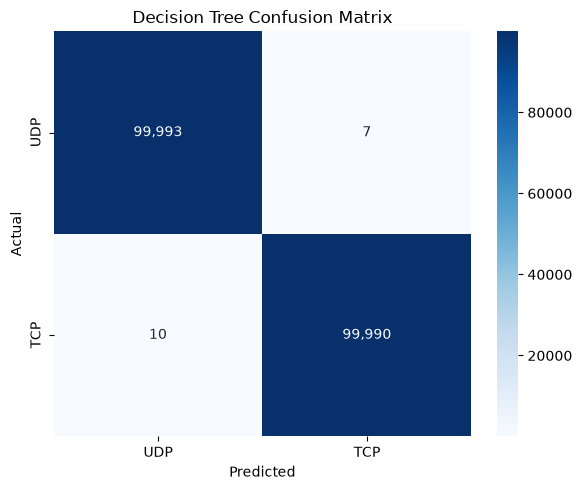

In [51]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_raw,
    y_pred_dt_final
)

print("Decision Tree Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test_raw,
        y_pred_dt_final,
        target_names=["UDP", "TCP"]
    )
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["UDP", "TCP"],
    yticklabels=["UDP", "TCP"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.tight_layout()
plt.show()

###  Among the evaluated classification models, Decision Tree achieved the best performance with 99.99% accuracy, 99.99% precision, 99.99% recall, and 99.99% F1-score. Logistic Regression and Linear SVM achieved approximately 92.77% accuracy. Random Forest also achieved 99.99% accuracy. Therefore, Decision Tree was selected as the best-performing model for TCP and UDP traffic classification in the prepared KT GameBox dataset.

# KT GameBox 5G Traffic Classification — ML Workflow

```text
10 CSV Files
        ↓
38,096,046 Packets
        ↓
TCP/UDP Balanced Dataset
        ↓
1,000,000 Samples
        ↓
Data Cleaning
        ↓
Remove `No.` + `Info`
        ↓
Time Processing
        ↓
Time Leakage Identified and Removed
        ↓
One-Hot Encoding
        ↓
Train-Test Split (80/20)
        ↓
Standard Scaling
        ↓
Feature Selection
        ↓
Model Training
        ↓
LR vs SVM vs DT vs RF
        ↓
Model Comparison
        ↓
Confusion Matrix
        ↓
**Decision Tree = Best Model**

## Best Model

**Decision Tree** was selected as the best-performing model.

- **Accuracy:** 99.99%
- **Precision:** 99.99%
- **Recall:** 99.99%
- **F1-Score:** 99.99%

**Best Model → Decision Tree**